In [15]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pywt

sys.path.insert(0, str(Path("../src").resolve()))

from fmlab.datatools.transforms import WaveletScalogram

### cmor1.5-1.0


In [16]:
dataset_path = Path("../artifacts/datasets/wesad_256_512_null_ecg")
annotations = pd.read_csv(dataset_path / "annotations.csv")
sample = np.load(dataset_path / annotations.iloc[0]["file"], allow_pickle=False)

transform = WaveletScalogram(fs=256, wavelet="cmor1.5-1.0", min_frequency=1, max_frequency=65, num_frequencies=100)
image = transform(sample)

In [17]:
coefficients, frequencies = pywt.cwt(sample.squeeze(), transform.widths, transform.wavelet, sampling_period=1 / transform.fs)
magnitude = np.abs(coefficients)
time = np.arange(magnitude.shape[1]) / transform.fs
time_grid, frequency_grid = np.meshgrid(time, frequencies)

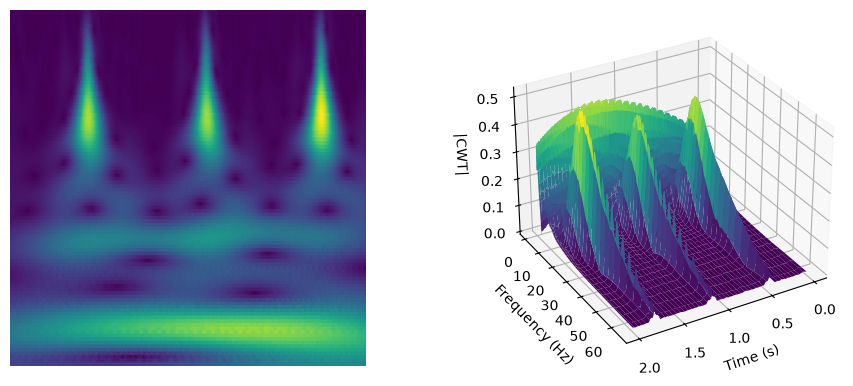

In [18]:
fig = plt.figure(figsize=(10, 4))
ax1 = fig.add_subplot(121)
ax1.imshow(image)
ax1.axis("off")

ax2 = fig.add_subplot(122, projection="3d")
ax2.plot_surface(time_grid, frequency_grid, magnitude, cmap="viridis")
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Frequency (Hz)")
ax2.set_zlabel("|CWT|")
ax2.view_init(elev=30, azim=60)
plt.tight_layout()
plt.show()

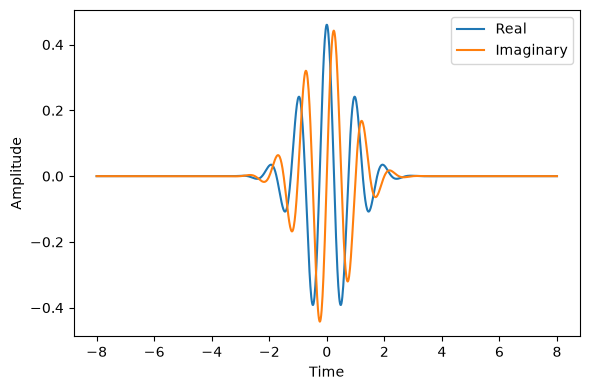

In [19]:
mother_wavelet = pywt.ContinuousWavelet(transform.wavelet)
wavelet_values, wavelet_time = mother_wavelet.wavefun(length=1024)

plt.figure(figsize=(6, 4))
plt.plot(wavelet_time, np.real(wavelet_values), label="Real")
plt.plot(wavelet_time, np.imag(wavelet_values), label="Imaginary")
plt.legend()
plt.xlabel("Time")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()

### morl


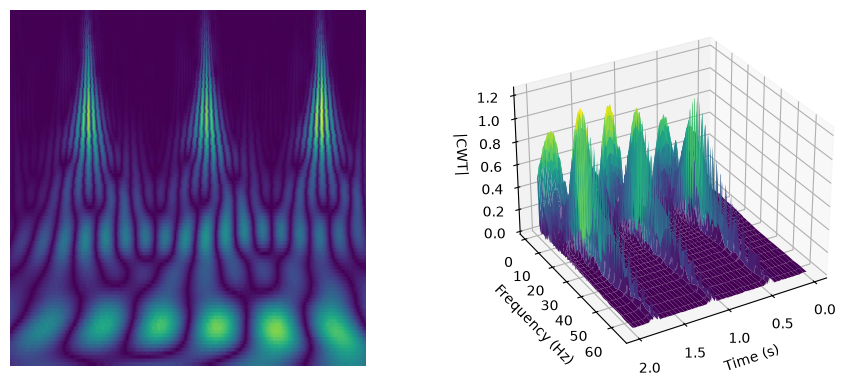

In [20]:
morl_transform = WaveletScalogram(fs=256, wavelet="morl", min_frequency=1, max_frequency=65, num_frequencies=100)
morl_image = morl_transform(sample)
morl_coefficients, morl_frequencies = pywt.cwt(sample.squeeze(), morl_transform.widths, morl_transform.wavelet, sampling_period=1 / morl_transform.fs)
morl_magnitude = np.abs(morl_coefficients)
morl_time = np.arange(morl_magnitude.shape[1]) / morl_transform.fs
morl_time_grid, morl_frequency_grid = np.meshgrid(morl_time, morl_frequencies)

fig = plt.figure(figsize=(10, 4))
ax1 = fig.add_subplot(121)
ax1.imshow(morl_image)
ax1.axis("off")

ax2 = fig.add_subplot(122, projection="3d")
ax2.plot_surface(morl_time_grid, morl_frequency_grid, morl_magnitude, cmap="viridis")
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Frequency (Hz)")
ax2.set_zlabel("|CWT|")
ax2.view_init(elev=30, azim=60)
plt.tight_layout()
plt.show()


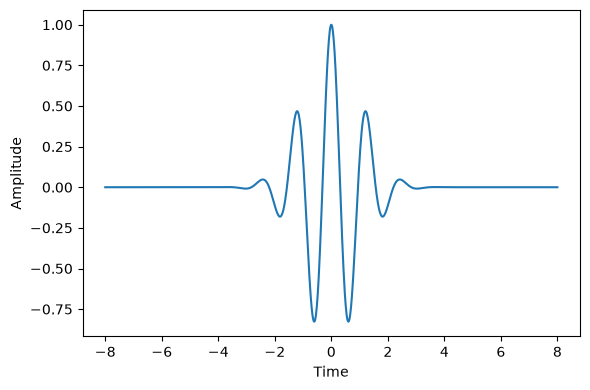

In [21]:
mother_wavelet = pywt.ContinuousWavelet(morl_transform.wavelet)
wavelet_values, wavelet_time = mother_wavelet.wavefun(length=1024)

plt.figure(figsize=(6, 4))
plt.plot(wavelet_time, np.real(wavelet_values), label="Real")
plt.xlabel("Time")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()

### mexh


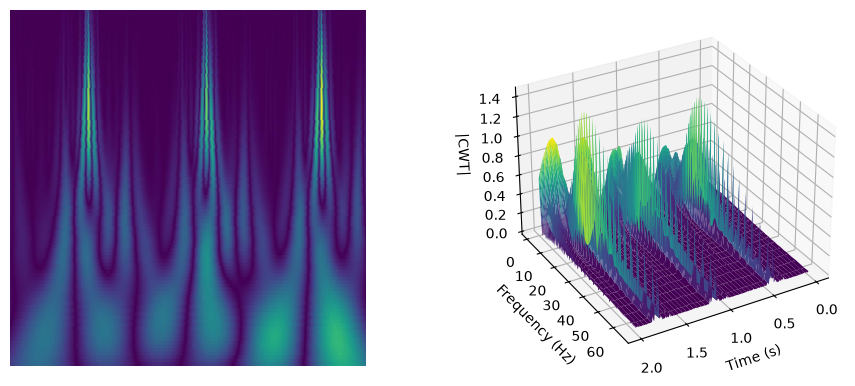

In [22]:
mexh_transform = WaveletScalogram(fs=256, wavelet="mexh", min_frequency=1, max_frequency=65, num_frequencies=100)
mexh_image = mexh_transform(sample)
mexh_coefficients, mexh_frequencies = pywt.cwt(sample.squeeze(), mexh_transform.widths, mexh_transform.wavelet, sampling_period=1 / mexh_transform.fs)
mexh_magnitude = np.abs(mexh_coefficients)
mexh_time = np.arange(mexh_magnitude.shape[1]) / mexh_transform.fs
mexh_time_grid, mexh_frequency_grid = np.meshgrid(mexh_time, mexh_frequencies)

fig = plt.figure(figsize=(10, 4))
ax1 = fig.add_subplot(121)
ax1.imshow(mexh_image)
ax1.axis("off")

ax2 = fig.add_subplot(122, projection="3d")
ax2.plot_surface(mexh_time_grid, mexh_frequency_grid, mexh_magnitude, cmap="viridis")
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Frequency (Hz)")
ax2.set_zlabel("|CWT|")
ax2.view_init(elev=30, azim=60)
plt.tight_layout()
plt.show()

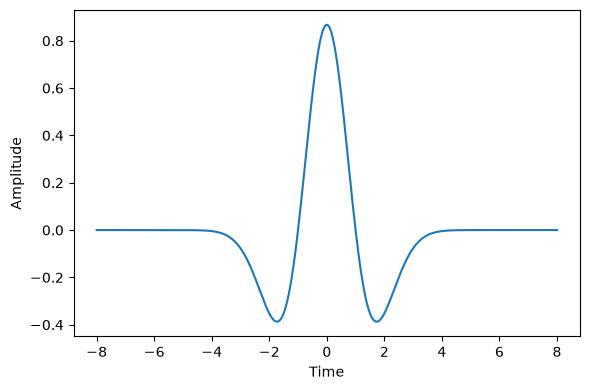

In [23]:
mother_wavelet = pywt.ContinuousWavelet(mexh_transform.wavelet)
wavelet_values, wavelet_time = mother_wavelet.wavefun(length=1024)

plt.figure(figsize=(6, 4))
plt.plot(wavelet_time, np.real(wavelet_values), label="Real")
plt.xlabel("Time")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()